Name : Swayam Kumbalwar

Roll No : 59

Section : B1

Batch :  B4

Project Title : Student Lifestyle and Academic Performance Analysis

Problem type: Regression.


1. Import Dataset + Basic Information

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("student_habits_performance.csv")

print(df.head())
print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
df.info()

  student_id  age  gender  study_hours_per_day  social_media_hours  \
0      S1000   23  Female                  0.0                 1.2   
1      S1001   20  Female                  6.9                 2.8   
2      S1002   21    Male                  1.4                 3.1   
3      S1003   23  Female                  1.0                 3.9   
4      S1004   19  Female                  5.0                 4.4   

   netflix_hours part_time_job  attendance_percentage  sleep_hours  \
0            1.1            No                   85.0          8.0   
1            2.3            No                   97.3          4.6   
2            1.3            No                   94.8          8.0   
3            1.0            No                   71.0          9.2   
4            0.5            No                   90.9          4.9   

  diet_quality  exercise_frequency parental_education_level internet_quality  \
0         Fair                   6                   Master          Average  

2. Data Cleaning

In [ ]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicates
print("\nDuplicate Rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# Correct inconsistent text
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Fill missing categorical values with mode
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values:
student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

Duplicate Rows: 0

Missing Values After Cleaning:
student_id                       0
age                              0
gender                           0
study_hours_per_day              0
social_media_hours               0
netflix_hours                    0
part_time_job                    0
attendance_percentage            0
sleep_hours                      0
diet_quality                 

3. Descriptive Statistics

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Mean:")
print(df[numeric_cols].mean())

print("\nMedian:")
print(df[numeric_cols].median())

print("\nMode:")
print(df[numeric_cols].mode().iloc[0])

print("\nMaximum:")
print(df[numeric_cols].max())

print("\nMinimum:")
print(df[numeric_cols].min())

print("\nStandard Deviation:")
print(df[numeric_cols].std())

print("\nVariance:")
print(df[numeric_cols].var())

print("\nQuartiles:")
print(df[numeric_cols].quantile([0.25, 0.50, 0.75]))

print("\nSummary Statistics:")
print(df.describe())

Mean:
age                      20.4980
study_hours_per_day       3.5501
social_media_hours        2.5055
netflix_hours             1.8197
attendance_percentage    84.1317
sleep_hours               6.4701
exercise_frequency        3.0420
mental_health_rating      5.4380
exam_score               69.6015
dtype: float64

Median:
age                      20.0
study_hours_per_day       3.5
social_media_hours        2.5
netflix_hours             1.8
attendance_percentage    84.4
sleep_hours               6.5
exercise_frequency        3.0
mental_health_rating      5.0
exam_score               70.5
dtype: float64

Mode:
age                       20.0
study_hours_per_day        3.5
social_media_hours         3.1
netflix_hours              0.0
attendance_percentage    100.0
sleep_hours                6.5
exercise_frequency         3.0
mental_health_rating       4.0
exam_score               100.0
Name: 0, dtype: float64

Maximum:
age                       24.0
study_hours_per_day        8.3
social

4. Outlier Detection — IQR

In [ ]:
numeric_cols = [
    "age",
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "attendance_percentage",
    "sleep_hours",
    "exercise_frequency",
    "mental_health_rating",
    "exam_score"
]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nOutliers in", col, ":", len(outliers))


Outliers in age : 0

Outliers in study_hours_per_day : 7

Outliers in social_media_hours : 5

Outliers in netflix_hours : 4

Outliers in attendance_percentage : 3

Outliers in sleep_hours : 2

Outliers in exercise_frequency : 0

Outliers in mental_health_rating : 0

Outliers in exam_score : 2


5. Heatmap

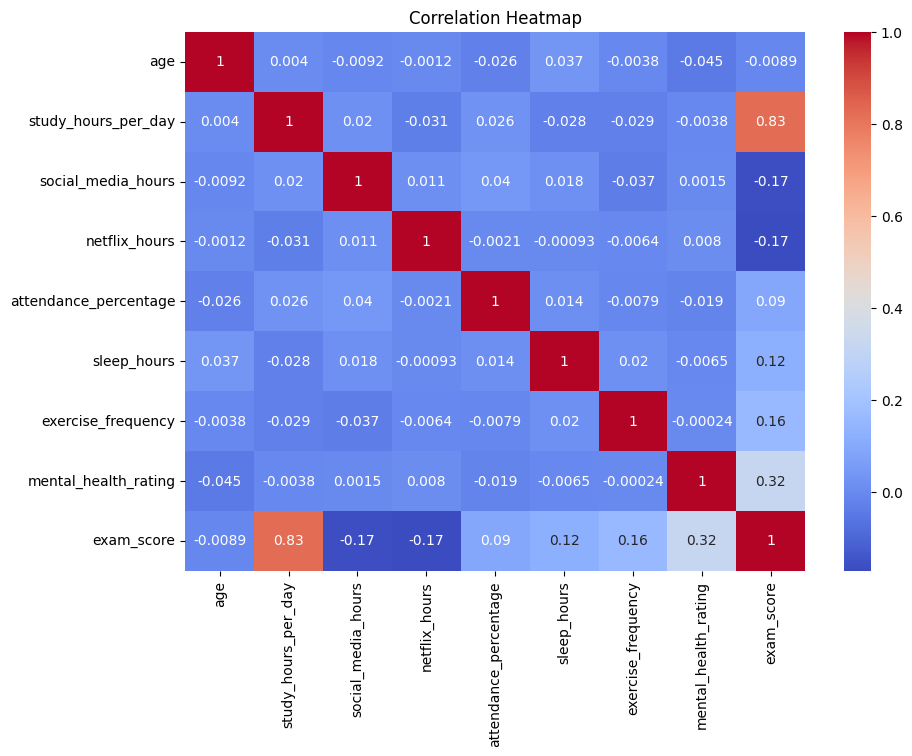

In [ ]:
plt.figure(figsize=(10,7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

6. Histogram — Exam Score

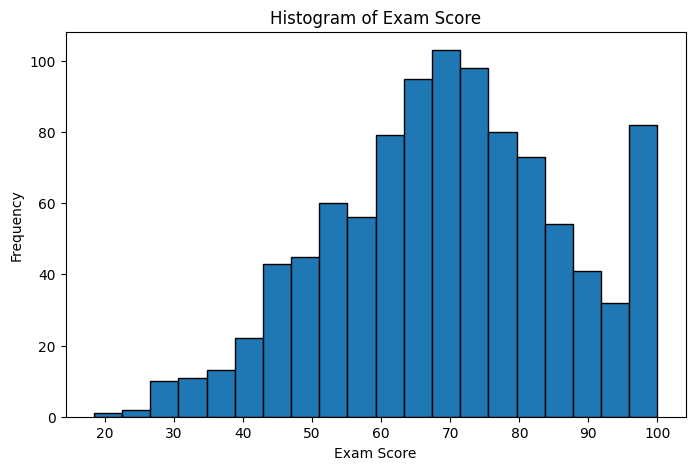

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["exam_score"], bins=20, edgecolor="black")

plt.title("Histogram of Exam Score")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")

plt.show()

7. Q-Q Plot

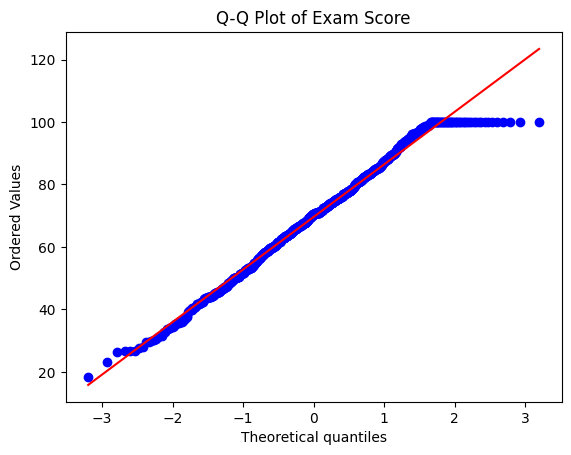

In [ ]:
stats.probplot(df["exam_score"], dist="norm", plot=plt)

plt.title("Q-Q Plot of Exam Score")
plt.show()

8. Five Number Summary

In [ ]:
print("Minimum:", df["exam_score"].min())
print("Q1:", df["exam_score"].quantile(0.25))
print("Median:", df["exam_score"].median())
print("Q3:", df["exam_score"].quantile(0.75))
print("Maximum:", df["exam_score"].max())

Minimum: 18.4
Q1: 58.475
Median: 70.5
Q3: 81.325
Maximum: 100.0


9. Bar Graph

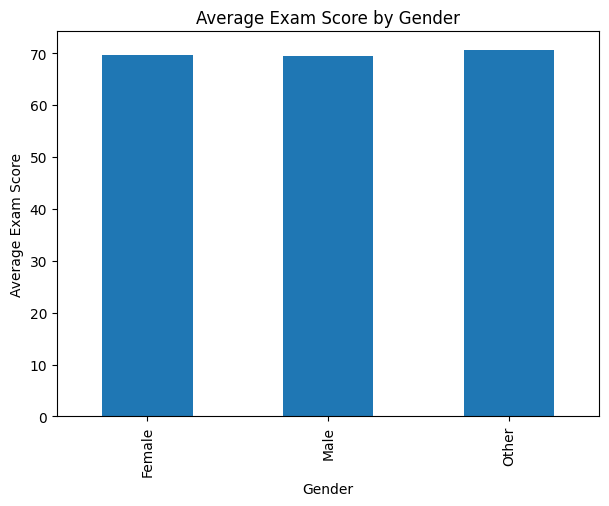

In [ ]:
df.groupby("gender")["exam_score"].mean().plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Average Exam Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Exam Score")
plt.show()

10. Scatter Plot

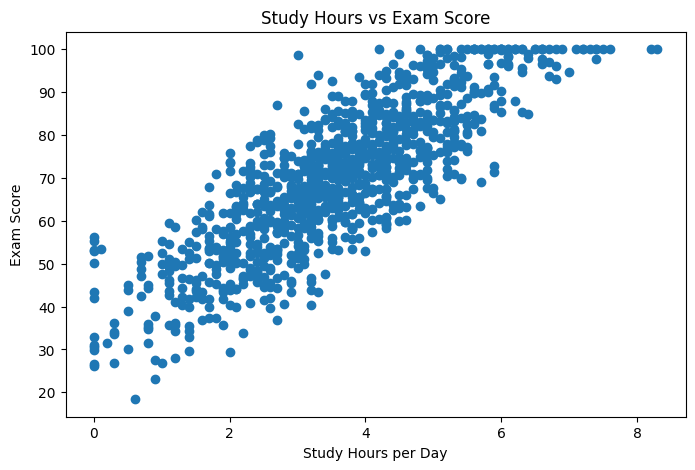

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["study_hours_per_day"],
    df["exam_score"]
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Study Hours per Day")
plt.ylabel("Exam Score")

plt.show()

11. Line Chart

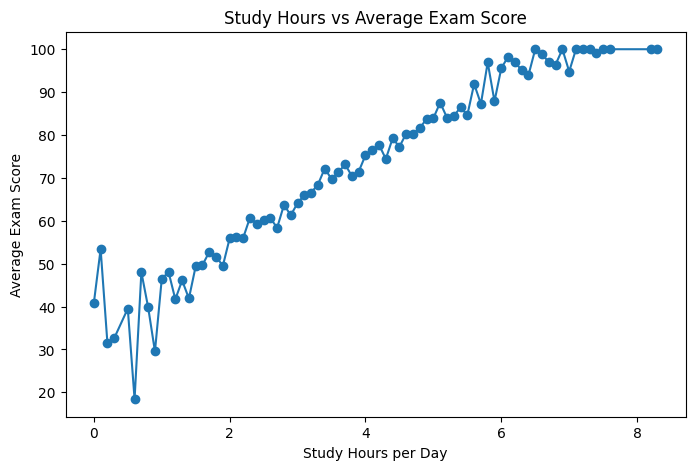

In [ ]:
temp = df.groupby("study_hours_per_day")["exam_score"].mean()

plt.figure(figsize=(8,5))

plt.plot(temp.index, temp.values, marker="o")

plt.title("Study Hours vs Average Exam Score")
plt.xlabel("Study Hours per Day")
plt.ylabel("Average Exam Score")

plt.show()

12. Probability — Uniform Distribution

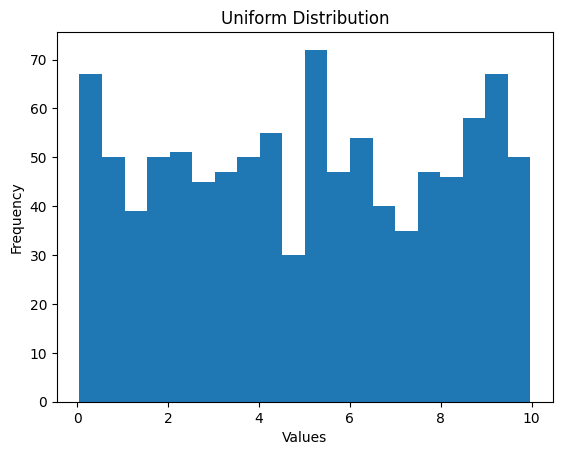

Mean: 5.0205464026281295
Variance: 8.670140044857757


In [ ]:
uniform = np.random.uniform(0, 10, 1000)

plt.hist(uniform, bins=20)

plt.title("Uniform Distribution")
plt.xlabel("Values")
plt.ylabel("Frequency")

plt.show()

print("Mean:", np.mean(uniform))
print("Variance:", np.var(uniform))

13. Normal Distribution

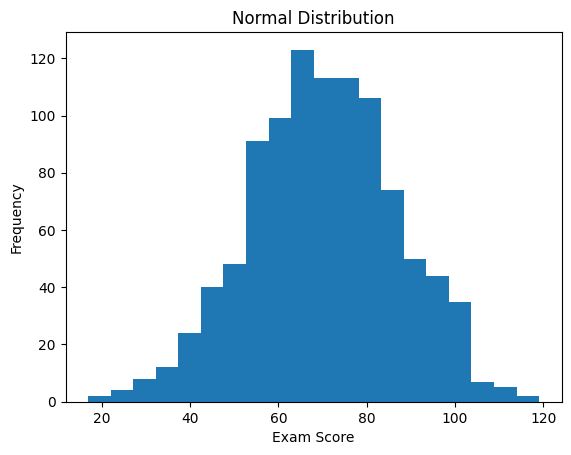

In [ ]:
normal = np.random.normal(
    df["exam_score"].mean(),
    df["exam_score"].std(),
    1000
)

plt.hist(normal, bins=20)

plt.title("Normal Distribution")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")

plt.show()

14. Binomial Distribution

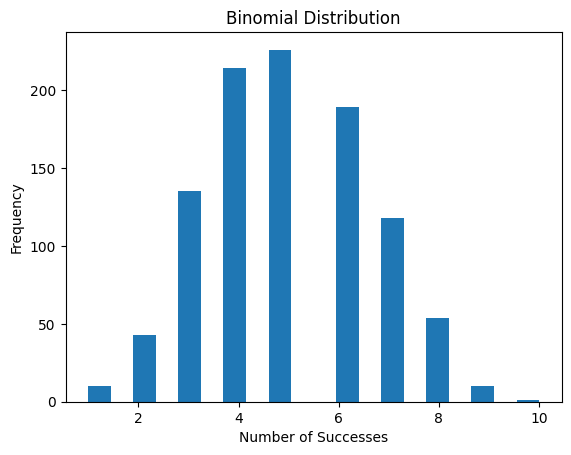

In [ ]:
binomial = np.random.binomial(
    n=10,
    p=0.5,
    size=1000
)

plt.hist(binomial, bins=20)

plt.title("Binomial Distribution")
plt.xlabel("Number of Successes")
plt.ylabel("Frequency")

plt.show()

15. Poisson Distribution

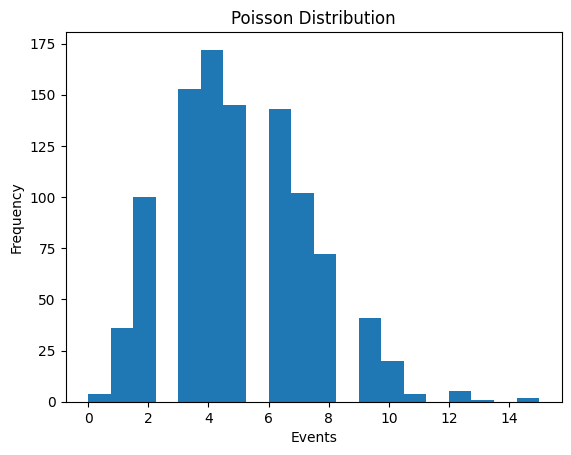

In [ ]:
poisson = np.random.poisson(
    lam=5,
    size=1000
)

plt.hist(poisson, bins=20)

plt.title("Poisson Distribution")
plt.xlabel("Events")
plt.ylabel("Frequency")

plt.show()

16. Simple Random Sampling

In [ ]:
sample1 = df.sample(n=20, random_state=1)

print("Simple Random Sample:")
print(sample1)

Simple Random Sample:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
507      S1507   19  Female                  2.7                 1.0   
818      S1818   20    Male                  2.3                 3.2   
452      S1452   22    Male                  4.8                 2.3   
368      S1368   19  Female                  2.8                 5.0   
242      S1242   20  Female                  5.3                 1.8   
929      S1929   17  Female                  5.7                 2.7   
262      S1262   21    Male                  3.0                 2.2   
810      S1810   19    Male                  4.4                 0.2   
318      S1318   23    Male                  2.2                 0.9   
49       S1049   22  Female                  6.1                 2.5   
446      S1446   19    Male                  3.7                 1.8   
142      S1142   20    Male                  3.2                 2.0   
968      S1968   22  Female               

17. Simple Random Sampling WITH Replacement

In [ ]:
sample2 = df.sample(
    n=20,
    replace=True,
    random_state=1
)

print("Simple Random Sampling With Replacement:")
print(sample2)

Simple Random Sampling With Replacement:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
37       S1037   17    Male                  4.3                 2.5   
235      S1235   20  Female                  3.8                 0.8   
908      S1908   23  Female                  5.6                 2.8   
72       S1072   17    Male                  3.4                 0.1   
767      S1767   24    Male                  3.1                 2.8   
905      S1905   18    Male                  2.6                 2.9   
715      S1715   24    Male                  5.6                 1.4   
645      S1645   21  Female                  1.1                 0.4   
847      S1847   18    Male                  2.3                 0.6   
960      S1960   17    Male                  7.1                 1.9   
144      S1144   24    Male                  4.3                 4.9   
129      S1129   20    Male                  0.3                 4.2   
972      S1972   17  Fe

18. Sampling without replacement

In [ ]:
sample3 = df.sample(
    n=20,
    replace=False,
    random_state=1
)

print("Sampling Without Replacement:")
print(sample3)

Sampling Without Replacement:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
507      S1507   19  Female                  2.7                 1.0   
818      S1818   20    Male                  2.3                 3.2   
452      S1452   22    Male                  4.8                 2.3   
368      S1368   19  Female                  2.8                 5.0   
242      S1242   20  Female                  5.3                 1.8   
929      S1929   17  Female                  5.7                 2.7   
262      S1262   21    Male                  3.0                 2.2   
810      S1810   19    Male                  4.4                 0.2   
318      S1318   23    Male                  2.2                 0.9   
49       S1049   22  Female                  6.1                 2.5   
446      S1446   19    Male                  3.7                 1.8   
142      S1142   20    Male                  3.2                 2.0   
968      S1968   22  Female       

19. systematic sampling

In [ ]:
k = 5

systematic_sample = df.iloc[::k]

print("Systematic Sample:")
print(systematic_sample)

Systematic Sample:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
0        S1000   23  Female                  0.0                 1.2   
5        S1005   24    Male                  7.2                 1.3   
10       S1010   19  Female                  4.6                 3.7   
15       S1015   21    Male                  3.1                 5.0   
20       S1020   22  Female                  3.8                 2.3   
..         ...  ...     ...                  ...                 ...   
975      S1975   18  Female                  2.6                 3.0   
980      S1980   20  Female                  3.7                 3.5   
985      S1985   18    Male                  5.7                 3.1   
990      S1990   18    Male                  3.2                 3.5   
995      S1995   21  Female                  2.6                 0.5   

     netflix_hours part_time_job  attendance_percentage  sleep_hours  \
0              1.1            No            

20. Stratified Sampling — on the basis of gender

In [ ]:
sample5 = df.groupby("gender", group_keys=False).sample(
    n=10,
    random_state=1
)

print("Stratified Sample:")
print(sample5)

print("\nSample Size:", len(sample5))

Stratified Sample:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
623      S1623   18  Female                  4.6                 1.2   
607      S1607   24  Female                  3.2                 3.0   
59       S1059   21  Female                  6.7                 2.2   
829      S1829   24  Female                  4.1                 5.4   
904      S1904   19  Female                  3.9                 0.7   
754      S1754   18  Female                  0.8                 3.3   
723      S1723   17  Female                  2.6                 3.0   
145      S1145   23  Female                  2.2                 6.2   
527      S1527   18  Female                  3.8                 0.7   
53       S1053   20  Female                  4.8                 2.0   
800      S1800   17    Male                  3.4                 1.5   
95       S1095   22    Male                  1.7                 2.9   
445      S1445   19    Male                  

21. cluster sampling - Department

In [ ]:
departments = df["parental_education_level"].unique()

selected = np.random.choice(
    departments,
    size=2,
    replace=False
)

cluster_sample = df[
    df["parental_education_level"].isin(selected)
]

print("Selected Clusters:")
print(selected)

print("\nCluster Sample:")
print(cluster_sample)

Selected Clusters:
['Bachelor' 'High School']

Cluster Sample:
    student_id  age  gender  study_hours_per_day  social_media_hours  \
1        S1001   20  Female                  6.9                 2.8   
2        S1002   21    Male                  1.4                 3.1   
7        S1007   21  Female                  4.3                 1.0   
8        S1008   23  Female                  4.4                 2.2   
9        S1009   18  Female                  4.8                 3.1   
..         ...  ...     ...                  ...                 ...   
995      S1995   21  Female                  2.6                 0.5   
996      S1996   17  Female                  2.9                 1.0   
997      S1997   20    Male                  3.0                 2.6   
998      S1998   24    Male                  5.4                 4.1   
999      S1999   19  Female                  4.3                 2.9   

     netflix_hours part_time_job  attendance_percentage  sleep_hours  \


22. Population Mean vs Sample Mean

In [ ]:
population = df["exam_score"]

sample = df.sample(
    n=20,
    random_state=1
)["exam_score"]

population_mean = population.mean()
sample_mean = sample.mean()

population_median = population.median()
sample_median = sample.median()

population_std = population.std()
sample_std = sample.std()

comparison = pd.DataFrame({
    "Statistics": [
        "Size",
        "Mean",
        "Median",
        "Standard Deviation"
    ],

    "Population": [
        len(population),
        population_mean,
        population_median,
        population_std
    ],

    "Simple Random Sampling": [
        len(sample),
        sample_mean,
        sample_median,
        sample_std
    ]
})

print(comparison)

           Statistics   Population  Simple Random Sampling
0                Size  1000.000000               20.000000
1                Mean    69.601500               73.840000
2              Median    70.500000               74.100000
3  Standard Deviation    16.888564               14.531143


23. Percentage Error

In [ ]:
error = abs(
    (sample_mean - population_mean)
    / population_mean
) * 100

print("Percentage Error in Mean:", error)

Percentage Error in Mean: 6.089667607738342


24. Sampling Distribution / CLT

In [ ]:
population = df["exam_score"].dropna().values

sample_size = 50
number_of_samples = 1000

sample_means = []

for i in range(number_of_samples):

    sample = np.random.choice(
        population,
        size=sample_size
    )

    sample_mean = np.mean(sample)

    sample_means.append(sample_mean)

sample_means = np.array(sample_means)

print("Population Mean:", np.mean(population))
print("Sample Means Mean:", np.mean(sample_means))

Population Mean: 69.6015
Sample Means Mean: 69.64872


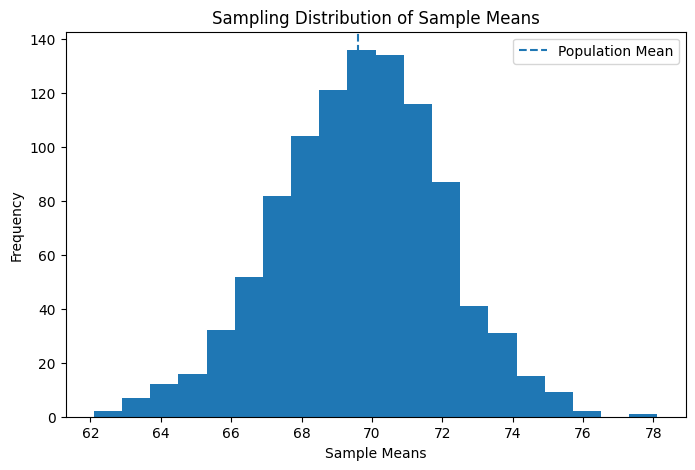

In [ ]:
# Sampling Distribution Plot
plt.figure(figsize=(8,5))

plt.hist(
    sample_means,
    bins=20
)

plt.axvline(
    np.mean(population),
    linestyle="--",
    label="Population Mean"
)

plt.title("Sampling Distribution of Sample Means")
plt.xlabel("Sample Means")
plt.ylabel("Frequency")
plt.legend()

plt.show()

25. CLT — Different Sample Sizes

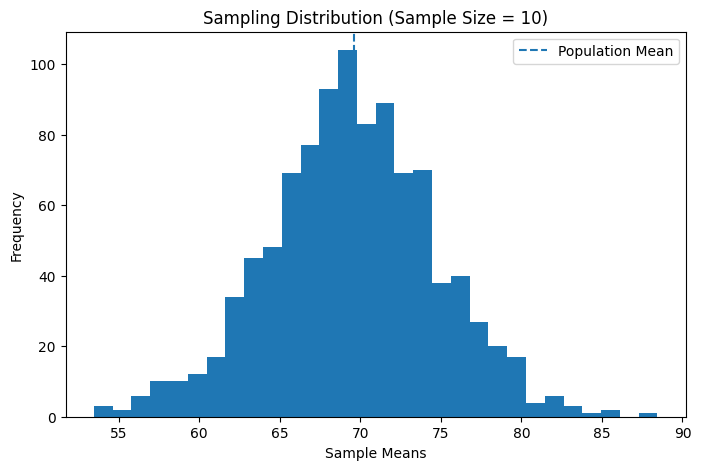

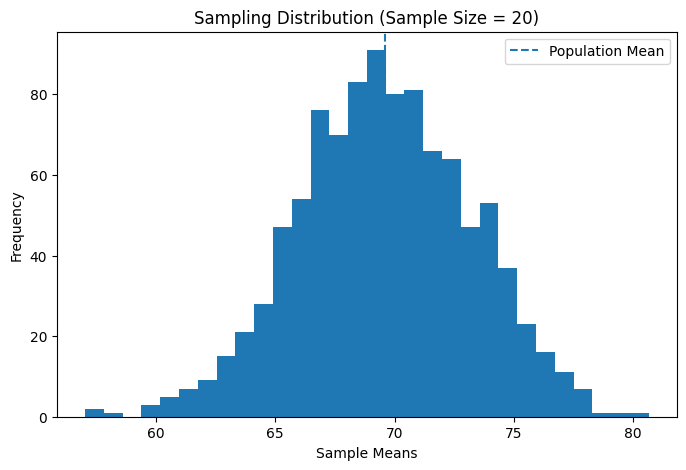

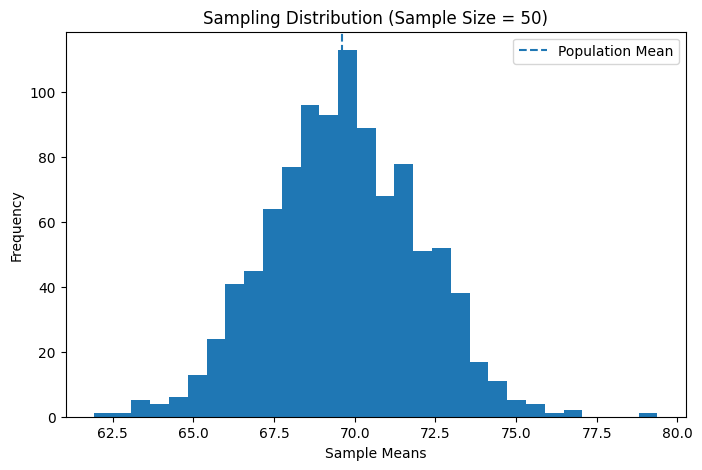

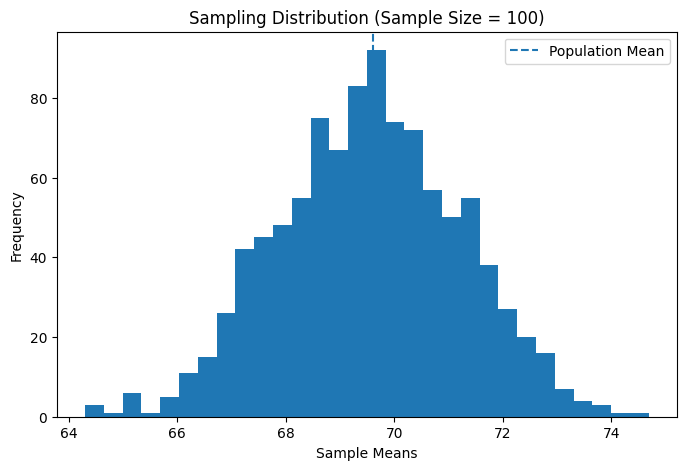

In [ ]:
population = df["exam_score"].dropna().values

sample_sizes = [10, 20, 50, 100]
number_of_samples = 1000

for n in sample_sizes:

    sample_means = []

    for i in range(number_of_samples):

        sample = np.random.choice(
            population,
            size=n
        )

        sample_means.append(np.mean(sample))

    plt.figure(figsize=(8,5))

    plt.hist(
        sample_means,
        bins=30
    )

    plt.axvline(
        np.mean(population),
        linestyle="--",
        label="Population Mean"
    )

    plt.title(
        "Sampling Distribution (Sample Size = " + str(n) + ")"
    )

    plt.xlabel("Sample Means")
    plt.ylabel("Frequency")
    plt.legend()

    plt.show()

In [ ]:
# Confidence Interval
marks = df["exam_score"]

mean = marks.mean()
std = marks.std()
n = len(marks)

confidence = 0.95
se = std / (n ** 0.5)

ci = stats.t.interval(confidence, df=n-1, loc=mean, scale=se)

ci

(np.float64(68.55348547489275), np.float64(70.64951452510725))

In [ ]:
# t-test
from scipy.stats import ttest_1samp

t_stat, p_value = ttest_1samp(df["exam_score"], popmean=50)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Accept H0")

T-statistic: 36.70257923807947
P-value: 2.0844381968239138e-187
Reject H0


In [ ]:
# z-test
from statsmodels.stats.weightstats import ztest

z_stat, p_value = ztest(df["exam_score"], value=50)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

Z-statistic: 36.70257923807947
P-value: 6.642986996358787e-295
Reject H0


In [ ]:
from scipy.stats import chi2_contingency
import pandas as pd

contingency_table = pd.crosstab(df["gender"], df["diet_quality"])

print("Contingency Table:")
print(contingency_table)

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("\nChi-Square Statistic:", chi2)
print("P-value:", p)
print("Degrees of Freedom:", dof)
print("\nExpected Frequencies:\n", expected)

if p < 0.05:
    print("\nConclusion: Significant association exists between gender and diet quality.")
else:
    print("\nConclusion: No significant association exists between gender and diet quality.")

Contingency Table:
diet_quality  Fair  Good  Poor
gender                        
Female         210   179    92
Male           209   185    83
Other           18    14    10

Chi-Square Statistic: 1.449938851724732
P-value: 0.8354706170451184
Degrees of Freedom: 4

Expected Frequencies:
 [[210.197 181.818  88.985]
 [208.449 180.306  88.245]
 [ 18.354  15.876   7.77 ]]

Conclusion: No significant association exists between gender and diet quality.


In [ ]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr

# Select numerical variables
x = df["study_hours_per_day"]
y = df["exam_score"]

# Covariance
covariance = df[["study_hours_per_day", "exam_score"]].cov().iloc[0, 1]
print("Covariance:", covariance)

# Pearson Correlation Coefficient
pearson_corr, pearson_p = pearsonr(x, y)
print("\nPearson Correlation Coefficient:", pearson_corr)
print("Pearson P-value:", pearson_p)

# Spearman Correlation Coefficient
spearman_corr, spearman_p = spearmanr(x, y)
print("\nSpearman Correlation Coefficient:", spearman_corr)
print("Spearman P-value:", spearman_p)

Covariance: 20.47652137137137

Pearson Correlation Coefficient: 0.8254185093960442
Pearson P-value: 4.595701453345048e-250

Spearman Correlation Coefficient: 0.8120778924640848
Spearman P-value: 1.0905806332350977e-235


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Load your dataset
df = pd.read_csv("student_habits_performance.csv")

print("Dataset:")
print(df.head())
print("\nDataset Shape:", df.shape)

# Select independent and dependent variables
X = df[["study_hours_per_day"]]
y = df["exam_score"]

print("\nIndependent Variable (X): Study Hours Per Day")
print("Dependent Variable (Y): Exam Score")

# Remove missing values in selected columns
data = pd.concat([X, y], axis=1).dropna()
X = data[["study_hours_per_day"]]
y = data["exam_score"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Standardize features for Ridge and Lasso
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 1. Simple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print("\nSIMPLE LINEAR REGRESSION")
print("=" * 50)
print("Intercept:", round(linear_model.intercept_, 2))
print("Slope:", round(linear_model.coef_[0], 2))
print(
    f"Regression Equation: Exam Score = "
    f"{linear_model.intercept_:.2f} + "
    f"{linear_model.coef_[0]:.2f} * Study Hours"
)

# 2. Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_pred = ridge_model.predict(X_test_scaled)

print("\nRIDGE REGRESSION")
print("=" * 50)
print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))
print("Coefficient:", round(ridge_model.coef_[0], 2))

# 3. Lasso Regression
lasso_model = Lasso(alpha=1.0, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)
lasso_pred = lasso_model.predict(X_test_scaled)

print("\nLASSO REGRESSION")
print("=" * 50)
print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))
print("Coefficient:", round(lasso_model.coef_[0], 2))

# 4. Decision Tree Regression
tree_model = DecisionTreeRegressor(
    max_depth=3, random_state=42
)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print("\nDECISION TREE REGRESSION")
print("=" * 50)
print("Max Depth:", tree_model.max_depth)

# 5. Random Forest Regression
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)

print("\nRANDOM FOREST REGRESSION")
print("=" * 50)
print("Number of Trees:", forest_model.n_estimators)
print("Maximum Depth:", forest_model.max_depth)

# Compare model performance
predictions = {
    "Linear Regression": linear_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree Regression": tree_pred,
    "Random Forest Regression": forest_pred
}

results = []

for model_name, pred in predictions.items():
    mse = mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append([model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2"]
)

print("\nMODEL COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

# Select the best model based on R2
models = {
    "Linear Regression": linear_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model,
    "Decision Tree Regression": tree_model,
    "Random Forest Regression": forest_model
}

best_model_name = results_df.loc[
    results_df["R2"].idxmax(), "Model"
]
best_model = models[best_model_name]

print("\nBest Model:", best_model_name)

# Save the best model and scaler
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")

print("\nModel and scaler saved successfully.")

# Reload saved model
model = joblib.load("best_model.pkl")
scaler = joblib.load("scaler.pkl")

# Prediction function
def predict_score(hours):
    if hours is None:
        return "Please enter study hours."

    if hours < 0:
        return "Study hours cannot be negative."

    input_data = pd.DataFrame({
        "study_hours_per_day": [float(hours)]
    })

    # Ridge and Lasso were trained on scaled inputs
    if best_model_name in ["Ridge Regression", "Lasso Regression"]:
        input_scaled = scaler.transform(input_data)
        predicted_score = model.predict(input_scaled)[0]
    else:
        predicted_score = model.predict(input_data)[0]

    return (
        f"Model: {best_model_name}\n"
        f"Predicted Exam Score: {predicted_score:.2f}"
    )

# Gradio interface
interface = gr.Interface(
    fn=predict_score,
    inputs=gr.Number(
        label="Study Hours Per Day",
        minimum=0
    ),
    outputs=gr.Textbox(label="Prediction Result"),
    title="Student Exam Score Prediction System",
    description=(
        "Enter the number of hours studied per day "
        "to predict the exam score."
    )
)

interface.launch(share=True)

Dataset:
  student_id  age  gender  study_hours_per_day  social_media_hours  \
0      S1000   23  Female                  0.0                 1.2   
1      S1001   20  Female                  6.9                 2.8   
2      S1002   21    Male                  1.4                 3.1   
3      S1003   23  Female                  1.0                 3.9   
4      S1004   19  Female                  5.0                 4.4   

   netflix_hours part_time_job  attendance_percentage  sleep_hours  \
0            1.1            No                   85.0          8.0   
1            2.3            No                   97.3          4.6   
2            1.3            No                   94.8          8.0   
3            1.0            No                   71.0          9.2   
4            0.5            No                   90.9          4.9   

  diet_quality  exercise_frequency parental_education_level internet_quality  \
0         Fair                   6                   Master          

In [ ]:

# ==========================================
# STUDENT LIFESTYLE & ACADEMIC PERFORMANCE
# CLASSIFICATION PRACTICALS 7-14
# ==========================================

import pandas as pd
import numpy as np
import joblib
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Load Dataset
df = pd.read_csv("student_habits_performance.csv")

print("Dataset Shape:", df.shape)
print(df.head())

# 2. Convert exam scores into classification categories
# Needs Improvement: below 50
# Average: 50 to below 75
# Good: 75 and above

df["performance_category"] = pd.cut(
    df["exam_score"],
    bins=[-np.inf, 50, 75, np.inf],
    labels=["Needs Improvement", "Average", "Good"],
    right=False
)

print("\nClass Distribution:")
print(df["performance_category"].value_counts())

# 3. Select features and target
X = df.drop(
    columns=["exam_score", "performance_category", "student_id"],
    errors="ignore"
)

y = df["performance_category"]

# Remove rows without a valid target
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Identify numerical and categorical columns automatically
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:", numeric_cols)
print("Categorical Features:", categorical_cols)

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_cols),
    ("categorical", categorical_transformer, categorical_cols)
])

# 5. Classification Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf")
}

# 6. Train and Evaluate Models
results = []
trained_models = {}

for name, classifier in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, predictions, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, average="weighted", zero_division=0
    )

    results.append([
        name, accuracy, precision, recall, f1
    ])

    trained_models[name] = model

    print(f"\n{name}")
    print("-" * 40)
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

# 7. Model Selection
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
)

results_df = results_df.sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)
print("Best Weighted F1 Score:", round(
    results_df.loc[0, "F1 Score"], 4
))

# 8. Save Best Model using Joblib
joblib.dump(best_model, "best_classification_model.pkl")
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

print("\nBest model saved successfully!")

# 9. Load Saved Model
model = joblib.load("best_classification_model.pkl")
feature_columns = joblib.load("feature_columns.pkl")

# 10. Prediction Function
def predict_performance(*values):

    input_df = pd.DataFrame(
        [values],
        columns=feature_columns
    )

    # Convert numeric features to numbers
    for col in numeric_cols:
        input_df[col] = pd.to_numeric(
            input_df[col], errors="coerce"
        )

    prediction = model.predict(input_df)[0]

    return f"Predicted Performance Category: {prediction}"

# 11. Create Prediction Interface
interface_inputs = []

for col in feature_columns:
    if col in numeric_cols:
        interface_inputs.append(
            gr.Number(label=col)
        )
    else:
        choices = sorted(
            df[col].dropna().astype(str).unique().tolist()
        )
        interface_inputs.append(
            gr.Dropdown(
                choices=choices,
                label=col
            )
        )

interface = gr.Interface(
    fn=predict_performance,
    inputs=interface_inputs,
    outputs=gr.Textbox(label="Predicted Performance"),
    title="Student Academic Performance Classifier",
    description=(
        "Enter student lifestyle and academic details "
        "to predict the performance category."
    )
)

interface.launch(share=True)


Dataset Shape: (1000, 16)
  student_id  age  gender  study_hours_per_day  social_media_hours  \
0      S1000   23  Female                  0.0                 1.2   
1      S1001   20  Female                  6.9                 2.8   
2      S1002   21    Male                  1.4                 3.1   
3      S1003   23  Female                  1.0                 3.9   
4      S1004   19  Female                  5.0                 4.4   

   netflix_hours part_time_job  attendance_percentage  sleep_hours  \
0            1.1            No                   85.0          8.0   
1            2.3            No                   97.3          4.6   
2            1.3            No                   94.8          8.0   
3            1.0            No                   71.0          9.2   
4            0.5            No                   90.9          4.9   

  diet_quality  exercise_frequency parental_education_level internet_quality  \
0         Fair                   6                  